# Complejidad algorítmica

La notación Big O describe cómo crece el coste de un algoritmo (tiempo o memoria) con el tamaño $n$ de la entrada, ignorando constantes y términos menores: $O(1) < O(\log n) < O(n) < O(n \log n) < O(n^2) < O(2^n)$. Se puede estimar contando operaciones o midiendo tiempos.

## 1. Contar operaciones

Contar cuántas veces se ejecuta el cuerpo del bucle en un código que no depende de $n$, un bucle que divide $n$ entre 2, un bucle simple y dos bucles anidados, y ver cómo crece al aumentar $n$.

In [1]:
import math

def ops_constante(n):
    return 1  # p. ej. lista[0]: no depende de n

def ops_logaritmica(n):
    ops = 0
    while n > 1:
        n //= 2
        ops += 1
    return ops

def ops_lineal(n):
    ops = 0
    for _ in range(n):
        ops += 1
    return ops

def ops_cuadratica(n):
    ops = 0
    for _ in range(n):
        for _ in range(n):
            ops += 1
    return ops

print(f"{'n':>6}{'O(1)':>8}{'O(log n)':>10}{'O(n)':>8}{'O(n²)':>10}")
for n in [10, 100, 1000]:
    assert ops_logaritmica(n) == int(math.log2(n)) and ops_lineal(n) == n and ops_cuadratica(n) == n * n
    print(f"{n:>6}{ops_constante(n):>8}{ops_logaritmica(n):>10}{ops_lineal(n):>8}{ops_cuadratica(n):>10}")

     n    O(1)  O(log n)    O(n)     O(n²)
    10       1         3      10       100
   100       1         6     100     10000
  1000       1         9    1000   1000000


## 2. Medir con `timeit`

Medir con `timeit` cuánto tarda `sum` sobre listas cada vez más grandes y comprobar que al duplicar $n$ el tiempo aproximadamente se duplica: es $O(n)$. Se toma el mínimo de varias repeticiones para reducir el ruido.

In [2]:
import timeit

def mide(funcion, *args, repeticiones=5, numero=10):
    return min(timeit.repeat(lambda: funcion(*args), repeat=repeticiones, number=numero)) / numero

anterior = None
for n in [100_000, 200_000, 400_000, 800_000]:
    t = mide(sum, list(range(n)))
    print(f"n = {n:>7}: {t * 1000:6.2f} ms", f"(x{t / anterior:.1f})" if anterior else "")
    anterior = t

n =  100000:   0.22 ms 
n =  200000:   0.46 ms (x2.1)
n =  400000:   0.99 ms (x2.1)


n =  800000:   2.20 ms (x2.2)


## 3. Búsqueda lineal y binaria

Buscar un valor en una lista ordenada recorriéndola ($O(n)$) o partiéndola por la mitad en cada paso ($O(\log n)$). Contar las comparaciones en el peor caso y comprobar el resultado contra `bisect`.

In [3]:
import bisect
import random

def busqueda_lineal(lista, x):
    comparaciones = 0
    for i, valor in enumerate(lista):
        comparaciones += 1
        if valor == x:
            return i, comparaciones
    return -1, comparaciones

def busqueda_binaria(lista, x):
    izq, der, comparaciones = 0, len(lista) - 1, 0
    while izq <= der:
        medio = (izq + der) // 2
        comparaciones += 1
        if lista[medio] == x:
            return medio, comparaciones
        if lista[medio] < x:
            izq = medio + 1
        else:
            der = medio - 1
    return -1, comparaciones

for _ in range(1000):
    lista = sorted(random.sample(range(100), random.randint(0, 30)))
    x = random.randrange(100)
    esperado = bisect.bisect_left(lista, x) if x in lista else -1
    assert busqueda_lineal(lista, x)[0] == busqueda_binaria(lista, x)[0] == esperado

for n in [10, 1000, 100_000, 1_000_000]:
    lista = list(range(n))
    print(f"n = {n:>9}: lineal {busqueda_lineal(lista, n - 1)[1]:>9}, binaria {busqueda_binaria(lista, n - 1)[1]:>3}")

n =        10: lineal        10, binaria   4
n =      1000: lineal      1000, binaria  10
n =    100000: lineal    100000, binaria  17


n =   1000000: lineal   1000000, binaria  20


## 4. Gráfica de tiempos frente a $n$

Escribir una función de cada clase y dibujar con `matplotlib` su tiempo frente a $n$: para $n \le 18$, donde ya se ve explotar $O(2^n)$, y para $n$ hasta 2000 sin la exponencial. Con el eje vertical en escala logarítmica se distinguen todas las curvas.

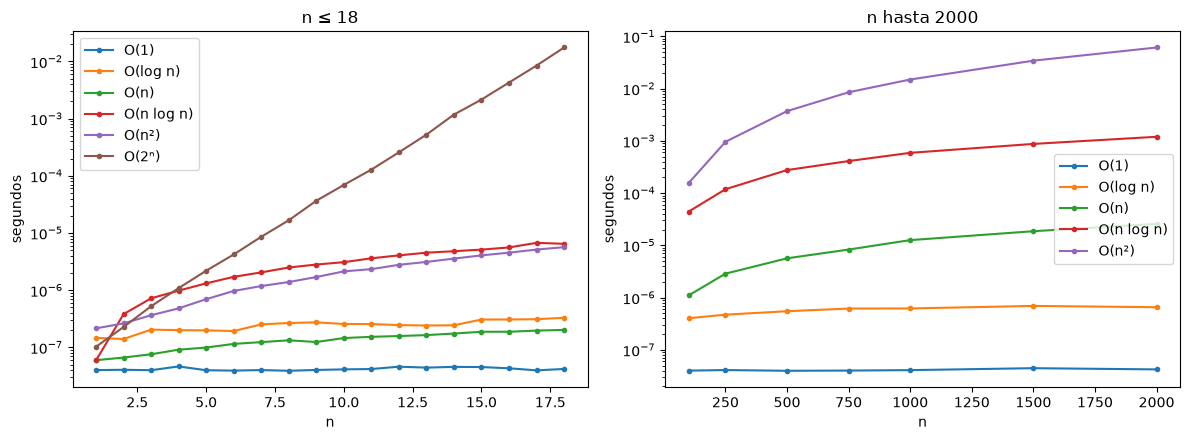

In [4]:
import matplotlib.pyplot as plt

def constante(datos):
    return datos[0]

def logaritmica(datos):
    return busqueda_binaria(datos, -1)

def lineal(datos):
    total = 0
    for x in datos:
        total += x
    return total

def n_log_n(datos):  # ordenación por mezcla
    if len(datos) <= 1:
        return datos
    medio = len(datos) // 2
    izq, der = n_log_n(datos[:medio]), n_log_n(datos[medio:])
    mezcla, i, j = [], 0, 0
    while i < len(izq) and j < len(der):
        if izq[i] <= der[j]:
            mezcla.append(izq[i])
            i += 1
        else:
            mezcla.append(der[j])
            j += 1
    return mezcla + izq[i:] + der[j:]

def cuadratica(datos):
    return sum(1 for x in datos for y in datos if x < y)

def exponencial(datos, i=0):  # recorre los 2ⁿ subconjuntos
    if i == len(datos):
        return 1
    return exponencial(datos, i + 1) + exponencial(datos, i + 1)

clases = {"O(1)": constante, "O(log n)": logaritmica, "O(n)": lineal,
          "O(n log n)": n_log_n, "O(n²)": cuadratica, "O(2ⁿ)": exponencial}

def tiempos(funcion, tamanos):
    resultado = []
    for n in tamanos:
        datos = list(range(n))
        # repite las funciones rápidas para que el reloj llegue a medirlas
        estimado = max(mide(funcion, datos, repeticiones=1, numero=1), 1e-7)
        resultado.append(mide(funcion, datos, repeticiones=3, numero=max(1, int(0.002 / estimado))))
    return resultado

pequenos = list(range(1, 19))
grandes = [100, 250, 500, 750, 1000, 1500, 2000]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre, funcion in clases.items():
    ax1.plot(pequenos, tiempos(funcion, pequenos), marker=".", label=nombre)
    if nombre != "O(2ⁿ)":
        ax2.plot(grandes, tiempos(funcion, grandes), marker=".", label=nombre)
ax1.set(yscale="log", xlabel="n", ylabel="segundos", title="n ≤ 18")
ax2.set(yscale="log", xlabel="n", ylabel="segundos", title="n hasta 2000")
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

## 5. Búsqueda en lista frente a `set`

`x in lista` recorre la lista ($O(n)$), mientras que `x in conjunto` usa una tabla hash ($O(1)$ de media). Medir ambas buscando un elemento que no está y aplicarlo a encontrar los elementos comunes de dos listas.

In [5]:
for n in [1_000, 10_000, 100_000, 1_000_000]:
    lista = list(range(n))
    conjunto = set(lista)
    t_lista = mide(lista.__contains__, -1, repeticiones=3, numero=5)
    t_set = mide(conjunto.__contains__, -1, repeticiones=3, numero=5)
    print(f"n = {n:>9}: lista {t_lista * 1e6:9.1f} µs, set {t_set * 1e6:5.2f} µs")

n =      1000: lista       4.0 µs, set  0.04 µs
n =     10000: lista      36.9 µs, set  0.04 µs
n =    100000: lista     376.4 µs, set  0.06 µs
n =   1000000: lista    4363.6 µs, set  0.04 µs


In [6]:
def comunes_lista(a, b):  # O(n·m)
    return [x for x in a if x in b]

def comunes_set(a, b):  # O(n + m)
    vistos = set(b)
    return [x for x in a if x in vistos]

a = random.sample(range(100_000), 5000)
b = random.sample(range(100_000), 5000)
assert comunes_lista(a, b) == comunes_set(a, b)
print(f"lista: {mide(comunes_lista, a, b, repeticiones=1, numero=1):.3f} s, set: {mide(comunes_set, a, b, repeticiones=1, numero=1):.4f} s")

lista: 0.099 s, set: 0.0004 s


## 6. Fibonacci ingenuo y memoizado

La versión recursiva directa recalcula los mismos valores una y otra vez: hace un número de llamadas que crece como $O(\varphi^n) \approx O(1{,}618^n)$. Guardando los resultados ya calculados (memoización con `lru_cache`) cada valor se calcula una sola vez: $O(n)$. Contar llamadas y medir tiempos.

In [7]:
from functools import lru_cache

llamadas = 0

def fib_ingenuo(n):
    global llamadas
    llamadas += 1
    return n if n < 2 else fib_ingenuo(n - 1) + fib_ingenuo(n - 2)

@lru_cache(maxsize=None)
def fib_memo(n):
    return n if n < 2 else fib_memo(n - 1) + fib_memo(n - 2)

for n in [5, 10, 15, 20, 25]:
    llamadas = 0
    fib_memo.cache_clear()
    assert fib_ingenuo(n) == fib_memo(n)
    print(f"fib({n:>2}) = {fib_memo(n):>6}: ingenuo {llamadas:>7} llamadas, memoizado {fib_memo.cache_info().misses:>3}")

print(f"fib(27) ingenuo: {mide(fib_ingenuo, 27, repeticiones=1, numero=1):.3f} s")
fib_memo.cache_clear()
print(f"fib(27) memoizado: {mide(fib_memo, 27, repeticiones=1, numero=1) * 1e6:.1f} µs")

fib( 5) =      5: ingenuo      15 llamadas, memoizado   6
fib(10) =     55: ingenuo     177 llamadas, memoizado  11
fib(15) =    610: ingenuo    1973 llamadas, memoizado  16
fib(20) =   6765: ingenuo   21891 llamadas, memoizado  21
fib(25) =  75025: ingenuo  242785 llamadas, memoizado  26
fib(27) ingenuo: 0.029 s
fib(27) memoizado: 8.5 µs


## 7. Complejidad espacial

La memoria extra también se mide en Big O. Comparar una lista por comprensión ($O(n)$) con un generador ($O(1)$), la suma recursiva (cada llamada ocupa pila: $O(n)$) con un bucle ($O(1)$), e invertir una lista con una copia ($O(n)$) o intercambiando en el sitio ($O(1)$). El pico de memoria se mide con `tracemalloc`.

In [8]:
import sys
import tracemalloc

def pico_memoria(funcion, *args):
    tracemalloc.start()
    funcion(*args)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico

n = 200_000
print("getsizeof lista:", sys.getsizeof([x * x for x in range(n)]), "generador:", sys.getsizeof(x * x for x in range(n)))
print("pico sum(lista):", pico_memoria(lambda: sum([x * x for x in range(n)])),
      "sum(generador):", pico_memoria(lambda: sum(x * x for x in range(n))))

getsizeof lista: 1624056 generador: 200


pico sum(lista): 8023998 sum(generador): 1383


In [9]:
def suma_recursiva(lista, i=0):
    return 0 if i == len(lista) else lista[i] + suma_recursiva(lista, i + 1)

def suma_bucle(lista):
    total = 0
    for x in lista:
        total += x
    return total

print(suma_recursiva(list(range(500))), suma_bucle(list(range(500))))
try:
    suma_recursiva(list(range(100_000)))
except RecursionError as e:
    print("RecursionError:", e)
print(suma_bucle(list(range(100_000))))

124750 124750
RecursionError: maximum recursion depth exceeded
4999950000


In [10]:
def invierte_copia(lista):
    return lista[::-1]

def invierte_en_sitio(lista):
    i, j = 0, len(lista) - 1
    while i < j:
        lista[i], lista[j] = lista[j], lista[i]
        i, j = i + 1, j - 1
    return lista

datos = list(range(100_000))
assert invierte_copia(datos) == invierte_en_sitio(datos[:])
print("pico copia:", pico_memoria(invierte_copia, datos), "en el sitio:", pico_memoria(invierte_en_sitio, datos))

pico copia: 800000 en el sitio: 128


## 8. Analizar fragmentos de código

Deducir la complejidad de cada fragmento y comprobarla contando operaciones para $n$ y $2n$. Al duplicar $n$ las operaciones se multiplican por $\approx 1$ si es $O(1)$, apenas crecen si es $O(\log n)$, $\approx 2$ si es $O(n)$, algo más de 2 si es $O(n \log n)$ y $\approx 4$ si es $O(n^2)$.

In [11]:
def fragmento_a(n):
    ops, i = 0, 1
    while i < n:
        i *= 2
        ops += 1
    return ops

def fragmento_b(n):
    ops = 0
    for i in range(n):
        for _ in range(i):  # 0 + 1 + ... + (n - 1) = n(n - 1) / 2
            ops += 1
    return ops

def fragmento_c(n):
    ops = 0
    for _ in range(n):
        for _ in range(10):  # constante, no depende de n
            ops += 1
    return ops

def fragmento_d(n):
    ops = 0
    for _ in range(n):
        j = 1
        while j < n:
            j *= 2
            ops += 1
    return ops

def fragmento_e(n):
    ops = 0
    for _ in range(100):
        ops += 1
    return ops

def clasifica(cociente):
    for limite, clase in [(1.05, "O(1)"), (1.5, "O(log n)"), (2.1, "O(n)"), (3, "O(n log n)"), (5, "O(n²)")]:
        if cociente < limite:
            return clase
    return "peor que O(n²)"

respuestas = {fragmento_a: "O(log n)", fragmento_b: "O(n²)", fragmento_c: "O(n)",
              fragmento_d: "O(n log n)", fragmento_e: "O(1)"}
for fragmento, respuesta in respuestas.items():
    cociente = fragmento(2048) / fragmento(1024)
    assert clasifica(cociente) == respuesta
    print(f"{fragmento.__name__}: x{cociente:.2f} -> {respuesta}")

fragmento_a: x1.10 -> O(log n)
fragmento_b: x4.00 -> O(n²)
fragmento_c: x2.00 -> O(n)
fragmento_d: x2.20 -> O(n log n)
fragmento_e: x1.00 -> O(1)


## 9. Dos números que suman un objetivo

Decidir si hay dos elementos de una lista que sumen `objetivo` de tres formas: probando todas las parejas ($O(n^2)$), ordenando y avanzando dos punteros desde los extremos ($O(n \log n)$) y recordando en un `set` los ya vistos ($O(n)$). Comprobar que coinciden y medirlas en el peor caso (no hay solución).

In [12]:
def dos_suma_parejas(nums, objetivo):
    for i in range(len(nums)):
        for j in range(i + 1, len(nums)):
            if nums[i] + nums[j] == objetivo:
                return True
    return False

def dos_suma_punteros(nums, objetivo):
    nums = sorted(nums)
    i, j = 0, len(nums) - 1
    while i < j:
        suma = nums[i] + nums[j]
        if suma == objetivo:
            return True
        if suma < objetivo:
            i += 1
        else:
            j -= 1
    return False

def dos_suma_set(nums, objetivo):
    vistos = set()
    for x in nums:
        if objetivo - x in vistos:
            return True
        vistos.add(x)
    return False

for _ in range(500):
    nums = [random.randint(-50, 50) for _ in range(random.randint(0, 20))]
    objetivo = random.randint(-100, 100)
    assert dos_suma_parejas(nums, objetivo) == dos_suma_punteros(nums, objetivo) == dos_suma_set(nums, objetivo)

nums = random.sample(range(1_000_000), 3000)
for funcion in (dos_suma_parejas, dos_suma_punteros, dos_suma_set):
    print(f"{funcion.__name__:<18}{mide(funcion, nums, -1, repeticiones=1, numero=1) * 1000:9.2f} ms")

dos_suma_parejas     121.12 ms
dos_suma_punteros      0.32 ms
dos_suma_set           0.17 ms
